# Лабораторная работа №3 «Кластеризация»

Цель — разделить двумерную выборку на 15 кластеров методами KMeans,
AgglomerativeClustering и DBSCAN и сравнить результаты.

In [1]:
%pip install -q numpy==1.26.4 scikit-learn==1.6.1

You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn import cluster
from sklearn import metrics

## Данные

Файл `s1.txt` содержит координаты точек на плоскости. Обе координаты имеют
одинаковый смысл и близкие диапазоны, поэтому используем исходный масштаб.

In [7]:
points = np.loadtxt("s1.txt")
print("Количество точек:", len(points))

Количество точек: 5000


## Построение графиков

Для всех методов используем одинаковые размеры графиков и масштаб осей.
Номера и цвета кластеров назначаются каждым методом независимо.
Шум DBSCAN отмечается серыми крестиками.

In [8]:
def plot_clusters(points, labels, title):
    """Строит график кластеров с легендой."""
    plt.figure(figsize=(9, 7))
    colors = plt.get_cmap("tab20")
    for label in np.unique(labels):
        group = points[labels == label]
        if label == -1:
            plt.scatter(
                group[:, 0], group[:, 1], s=15,
                color="gray", marker="x", label="Шум"
            )
        else:
            plt.scatter(
                group[:, 0], group[:, 1], s=10,
                color=colors(int(label)), label=f"Кластер {label + 1}"
            )
    plt.title(title)
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.axis("equal")
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
    plt.tight_layout()
    plt.show()

## Кластеризация

Для KMeans и AgglomerativeClustering задаём 15 кластеров. У KMeans используем
10 инициализаций и фиксируем `random_state` для воспроизводимости.
Для иерархического метода выбираем `ward`: объединяются группы с наименьшим
приростом внутрикластерной суммы квадратов отклонений.

Для DBSCAN параметры подобраны на этой выборке: `eps=27500`, `min_samples=10`.
`eps` задаёт радиус окрестности в исходных единицах координат, а `min_samples` —
минимальное количество точек в ней, включая саму точку, для признания её основной.
Число кластеров заранее не задаётся; при выбранных параметрах получается 15.
Метка `-1` обозначает шум и отдельным кластером не считается.

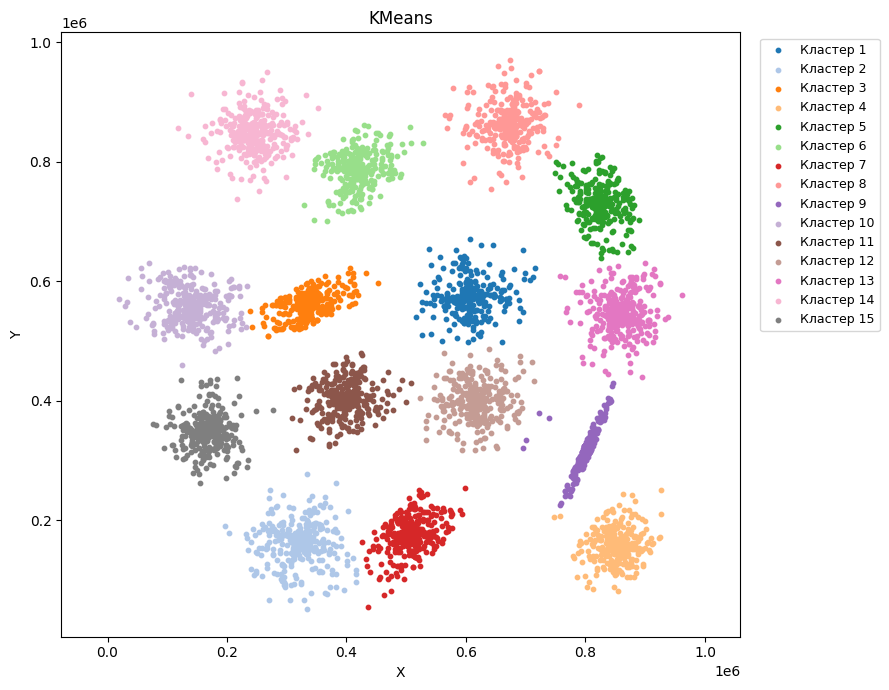

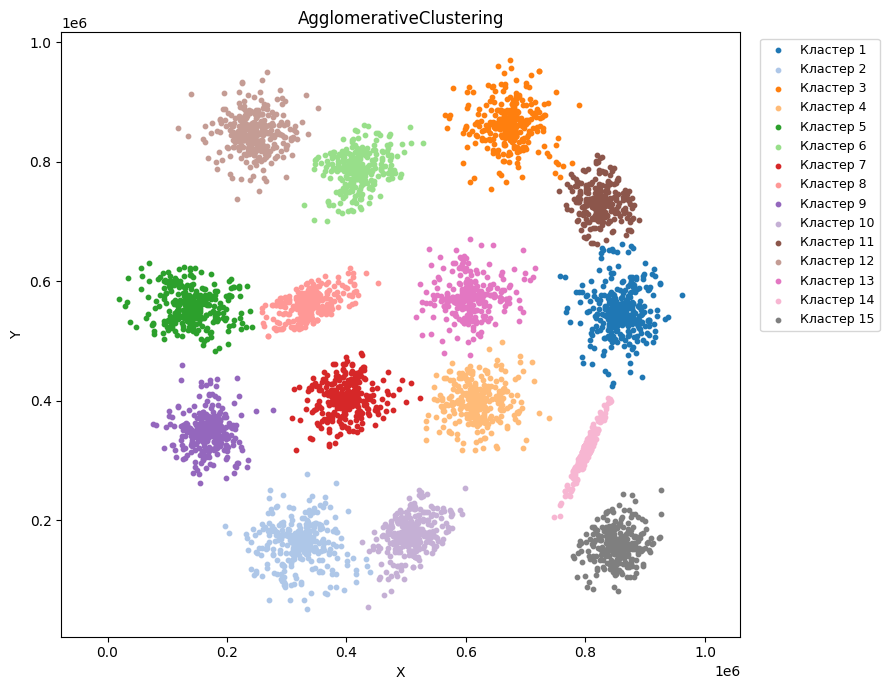

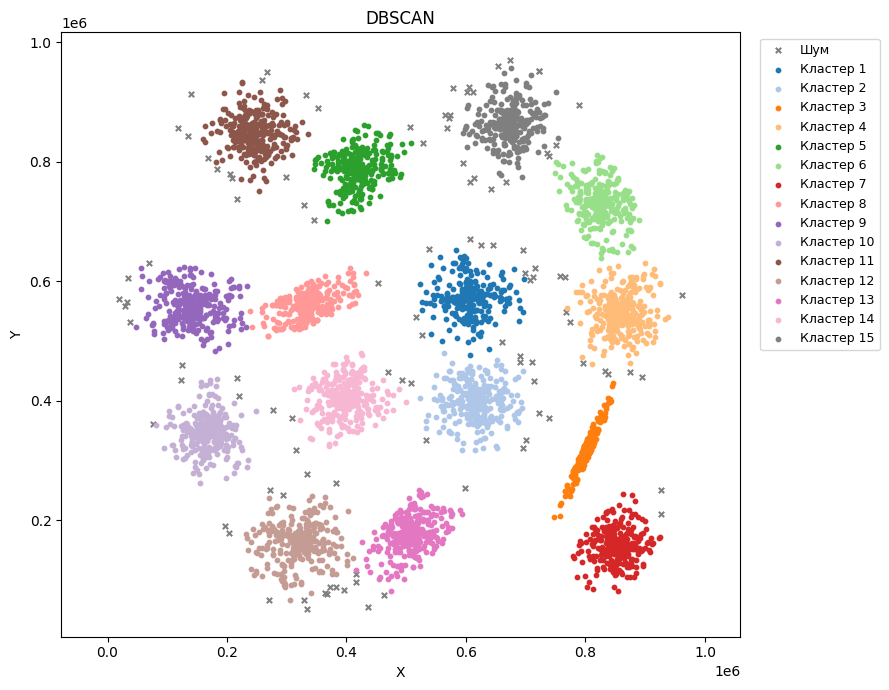

In [9]:
models = {
    "KMeans": cluster.KMeans(n_clusters=15, random_state=42, n_init=10),
    "AgglomerativeClustering": cluster.AgglomerativeClustering(
        n_clusters=15, linkage="ward"
    ),
    "DBSCAN": cluster.DBSCAN(eps=27500, min_samples=10),
}
results = {}

for name, model in models.items():
    labels = model.fit_predict(points)
    results[name] = labels
    plot_clusters(points, labels, name)

## Сравнение результатов

Посчитаем количество кластеров, число точек шума и коэффициент силуэта.
Силуэт сравнивает близость точки к своему кластеру и к соседнему; значения ближе
к 1 означают более компактные и разделённые группы. Шум исключаем из расчёта.
Поэтому оценка DBSCAN относится только к оставшимся точкам, и напрямую объявлять
его лучшим по силуэту нельзя. Эталонных меток в исходном файле нет.

In [10]:
print(f"{'Метод':<25} {'Кластеры':>8} {'Шум':>6} {'Силуэт':>8}")
for name, labels in results.items():
    mask = labels != -1
    cluster_count = len(np.unique(labels[mask]))
    noise_count = np.sum(labels == -1)
    score = metrics.silhouette_score(points[mask], labels[mask])
    print(f"{name:<25} {cluster_count:>8} {noise_count:>6} {score:>8.3f}")

Метод                     Кластеры    Шум   Силуэт
KMeans                          15      0    0.711
AgglomerativeClustering         15      0    0.709
DBSCAN                          15    108    0.725


## Выводы

Все три метода выделили 15 кластеров. На графиках основные группы совпадают,
но принадлежность отдельных точек на границах различается. Видны как округлые,
так и вытянутые группы; при выбранных параметрах все методы разделили их.

KMeans и AgglomerativeClustering распределили все 5000 точек по кластерам.
Их силуэты близки: 0,711 и 0,709 соответственно. Это согласуется с визуально
похожими результатами; небольшая разница не означает существенного превосходства.

DBSCAN отнёс 108 точек (2,16%) к шуму, преимущественно на периферии групп.
Силуэт оставшихся 4892 точек равен 0,725. Его увеличение частично связано
с исключением периферийных точек, поэтому это не доказательство лучшей
кластеризации всей выборки.

При предварительном подборе с `min_samples=10` радиус 25000 дал 15 кластеров
и 160 точек шума, 27500 — 15 кластеров и 108 точек шума, а 30000 — уже
11 кластеров и 75 точек шума. Выбрано значение 27500: среди этих вариантов
оно сохраняет 15 групп и оставляет меньше шума, чем 25000. Увеличение радиуса
до 30000 объединяет соседние группы. Эти параметры подобраны для `s1.txt`
и не гарантируют 15 кластеров на других данных.

| Метод | Преимущества | Недостатки и применимость |
| --- | --- | --- |
| KMeans | Простой, обычно быстрый; хорошо разделяет компактные округлые группы. | Нужно заранее задать число кластеров. Чувствителен к выбросам и начальным центрам; плохо подходит для вытянутых и невыпуклых групп. |
| AgglomerativeClustering | Строит иерархию объединений, не требует случайного выбора центров. | На больших выборках требует больше ресурсов. Результат зависит от способа объединения; выбранный Ward ориентирован на компактные группы и не выделяет шум. |
| DBSCAN | Выделяет шум, находит плотные группы сложной формы без задания их числа. | Чувствителен к масштабу, `eps` и `min_samples`. Единый радиус плохо подходит для групп сильно различающейся плотности; близкие группы могут объединяться. |

Для этой выборки с компактными группами KMeans — подходящий простой метод.
Иерархическая кластеризация полезна, когда важна структура объединений.
DBSCAN полезен при наличии шума и групп сложной формы, если их плотности сопоставимы.